Can we predict whether an app will receive a high rating

# **Experimentation Phase**

## **0_Setup**

In [40]:
import pandas as pd
import numpy as np

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

## **1_Load and Inspect the Data**

In [41]:
applications = pd.read_csv('Applications_Compiled.csv')

In [42]:
# formats all floats to two decimal places
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [43]:
applications.head()

,AppName,Category,Rating,ReviewCount,Size_MB,Installs,Type,Price,ContentRating,LastUpdated,MinAndroidVer
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.10,159.00,19.00,"10,000.00",Free,0.00,Everyone,2018-01-07,4.0.3
1,Coloring book moana,ART_AND_DESIGN,3.90,967.00,14.00,"500,000.00",Free,0.00,Everyone,2018-01-15,4.0.3
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.70,"87,510.00",8.70,"5,000,000.00",Free,0.00,Everyone,2018-08-01,4.0.3
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.50,"215,644.00",25.00,"50,000,000.00",Free,0.00,Teen,2018-06-08,4.2
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.30,967.00,2.80,"100,000.00",Free,0.00,Everyone,2018-06-20,4.4


In [44]:
applications.shape

(2199861, 11)

In [45]:
applications.columns

Index(['AppName', 'Category', 'Rating', 'ReviewCount', 'Size_MB', 'Installs',
       'Type', 'Price', 'ContentRating', 'LastUpdated', 'MinAndroidVer'],
      dtype='str')

In [46]:
applications.info()

<class 'pandas.DataFrame'>
RangeIndex: 2199861 entries, 0 to 2199860
Data columns (total 11 columns):
 #   Column         Dtype  
---  ------         -----  
 0   AppName        str    
 1   Category       str    
 2   Rating         float64
 3   ReviewCount    float64
 4   Size_MB        float64
 5   Installs       float64
 6   Type           str    
 7   Price          float64
 8   ContentRating  str    
 9   LastUpdated    str    
 10  MinAndroidVer  str    
dtypes: float64(5), str(6)
memory usage: 184.6 MB


In [47]:
applications.describe()

,Rating,ReviewCount,Size_MB,Installs,Price
count,"2,199,861.00","2,199,861.00","2,199,861.00","2,199,861.00","2,199,861.00"
mean,2.19,"2,309.22",19.32,"119,007.87",0.11
std,2.11,"99,346.61",23.97,"3,903,970.46",2.86
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,4.90,50.00,0.00
50%,2.90,6.00,10.00,500.00,0.00
75%,4.30,40.00,25.00,"5,000.00",0.00
max,5.00,"56,025,424.00","1,020.00","1,000,000,000.00",400.00


In [48]:
applications.isna().sum()

AppName             0
Category            0
Rating              0
ReviewCount         0
Size_MB             0
Installs            0
Type                0
Price               0
ContentRating       0
LastUpdated         0
MinAndroidVer    6323
dtype: int64

In [49]:
# Create a copy of the dataframe
applications_copy = applications.copy()
applications_copy.head()

,AppName,Category,Rating,ReviewCount,Size_MB,Installs,Type,Price,ContentRating,LastUpdated,MinAndroidVer
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.10,159.00,19.00,"10,000.00",Free,0.00,Everyone,2018-01-07,4.0.3
1,Coloring book moana,ART_AND_DESIGN,3.90,967.00,14.00,"500,000.00",Free,0.00,Everyone,2018-01-15,4.0.3
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.70,"87,510.00",8.70,"5,000,000.00",Free,0.00,Everyone,2018-08-01,4.0.3
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.50,"215,644.00",25.00,"50,000,000.00",Free,0.00,Teen,2018-06-08,4.2
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.30,967.00,2.80,"100,000.00",Free,0.00,Everyone,2018-06-20,4.4


In [50]:
# Convert "LastUpdated" column to datetime
applications_copy['LastUpdated'] = pd.to_datetime(applications_copy['LastUpdated'], errors='coerce')

## **2_Handling Missing Values**

In [51]:
# Use 'mode' to impute missing values for "MinAndroidVer"

imputer = SimpleImputer(strategy='most_frequent')

applications_copy[['MinAndroidVer']] = imputer.fit_transform(applications_copy[['MinAndroidVer']])

In [52]:
applications_copy.isna().sum()

AppName          0
Category         0
Rating           0
ReviewCount      0
Size_MB          0
Installs         0
Type             0
Price            0
ContentRating    0
LastUpdated      0
MinAndroidVer    0
dtype: int64

## **3_Encoding (Categorical Data)**

### Column: Category

In [53]:
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

category_encoded = ohe.fit_transform(applications_copy[['Category']])
applications_copy_cols = ohe.get_feature_names_out(['Category'])
category_df = pd.DataFrame(category_encoded, columns=applications_copy_cols)

### Column: Type

In [54]:
applications_copy['Type'].unique()

<StringArray>
['Free', 'Paid']
Length: 2, dtype: str

In [55]:
le = LabelEncoder()

applications_copy['Type_enc'] = le.fit_transform(applications_copy['Type'])

### Column: ContentRating

In [56]:
contentrating_encoded = ohe.fit_transform(applications_copy[['ContentRating']])
applications_copy_cols1 = ohe.get_feature_names_out(['ContentRating'])
contentrating_df = pd.DataFrame(contentrating_encoded, columns=applications_copy_cols1)

### Column: MinAndroidVer

In [57]:
androidver_encoded = ohe.fit_transform(applications_copy[['MinAndroidVer']])
applications_copy_cols2 = ohe.get_feature_names_out(['MinAndroidVer'])
androidver_df = pd.DataFrame(androidver_encoded, columns=applications_copy_cols2)

## **4_Feature Engineering 'LastUpdated' Column**

In [58]:
# Reference date set to the newest update in the dataset
max_date = applications_copy['LastUpdated'].max()

# Continuous feature: App update age in days
applications_copy['Days_Since_Update'] = (max_date - applications_copy['LastUpdated']).dt.days

In [59]:
applications_copy['Update_Year'] = applications_copy['LastUpdated'].dt.year
applications_copy['Update_Month'] = applications_copy['LastUpdated'].dt.month
applications_copy['Update_DayOfWeek'] = applications_copy['LastUpdated'].dt.dayofweek  # 0=Monday, 6=Sunday
applications_copy['Is_Weekend'] = applications_copy['Update_DayOfWeek'].isin([5, 6]).astype(int)

In [60]:
applications_copy['Month_Sin'] = np.sin(2 * np.pi * applications_copy['Update_Month'] / 12)
applications_copy['Month_Cos'] = np.cos(2 * np.pi * applications_copy['Update_Month'] / 12)

In [61]:
# Impute continuous elapsed days with median
imputer_date = SimpleImputer(strategy='median')
applications_copy[['Days_Since_Update']] = imputer_date.fit_transform(applications_copy[['Days_Since_Update']])

In [62]:
applications_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 2199861 entries, 0 to 2199860
Data columns (total 19 columns):
 #   Column             Dtype         
---  ------             -----         
 0   AppName            str           
 1   Category           str           
 2   Rating             float64       
 3   ReviewCount        float64       
 4   Size_MB            float64       
 5   Installs           float64       
 6   Type               str           
 7   Price              float64       
 8   ContentRating      str           
 9   LastUpdated        datetime64[us]
 10  MinAndroidVer      str           
 11  Type_enc           int64         
 12  Days_Since_Update  float64       
 13  Update_Year        int32         
 14  Update_Month       int32         
 15  Update_DayOfWeek   int32         
 16  Is_Weekend         int64         
 17  Month_Sin          float64       
 18  Month_Cos          float64       
dtypes: datetime64[us](1), float64(8), int32(3), int64(2), str(5)
memory usage:

## **5_Feature Scaling (Numerical Data)**

### Rating as the Dependent Variable

***Can we predict whether an app will receive a rating of greater than 4.0?***

#### Train/Test Split

In [63]:
num_cols_1 = ['ReviewCount', 'Size_MB', 'Installs', 'Price', 'Days_Since_Update', 'Update_Year']

X_application_copy = applications_copy[num_cols_1]
y_application_copy = applications_copy['Rating']

In [64]:
X_train_application_copy, X_test_application_copy, y_train_application_copy, y_test_application_copy = train_test_split(
    X_application_copy, y_application_copy, test_size=0.2, random_state=42
)

In [65]:
print(X_train_application_copy.shape)
print(X_test_application_copy.shape)

(1759888, 6)
(439973, 6)


#### Scaling

In [66]:
scaler = StandardScaler()

X_train_scale = scaler.fit_transform(X_train_application_copy) # TRAINING DATA ONLY
X_test_scale = scaler.transform(X_test_application_copy) # TEST DATA

# **Pipeline + ColumnTransformer**

In [67]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

X = applications_copy.drop(columns=['Rating', 'AppName', 'LastUpdated'])
y = applications_copy['Rating']

X_train_application_copy, X_test_application_copy, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)


num_cols_1 = ['ReviewCount', 'Size_MB', 'Installs', 'Price', 'Days_Since_Update', 'Update_Year']
cat_cols = ['Category', 'ContentRating', 'Type', 'MinAndroidVer']
passthrough_cols = ['Is_Weekend', 'Month_Sin', 'Month_Cos']


# Pipeline
num_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy='median')),
    ("scale", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy='most_frequent')),
    ("encode", OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", num_pipeline, num_cols_1),
    ("cat", cat_pipeline, cat_cols),
    ("pass", 'passthrough', passthrough_cols)
])

# Train-test split
X_train_transformed = preprocessor.fit_transform(X_train_application_copy)

## Clasiffication Model

In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = pd.read_csv('Applications_Compiled.csv')

df['LastUpdated'] = pd.to_datetime(df['LastUpdated'], errors='coerce')

# 1. Clean rows BEFORE splitting
df = df.drop_duplicates(subset='AppName')
df = df.dropna(subset=['Rating'])

# 2. Row-wise feature engineering (no fitting, so no leakage)
max_date = df['LastUpdated'].max()
df['Days_Since_Update'] = (max_date - df['LastUpdated']).dt.days
df['Update_Year'] = df['LastUpdated'].dt.year
month = df['LastUpdated'].dt.month
df['Is_Weekend'] = df['LastUpdated'].dt.dayofweek.isin([5, 6]).astype(float)
df['Month_Sin'] = np.sin(2 * np.pi * month / 12)
df['Month_Cos'] = np.cos(2 * np.pi * month / 12)

# 3. Binary target, created once
y = (df['Rating'] >= 4.0).astype(int)

num_cols = ['ReviewCount', 'Size_MB', 'Installs', 'Price', 'Days_Since_Update', 'Update_Year']
cat_cols = ['Category', 'ContentRating', 'Type', 'MinAndroidVer']
pass_cols = ['Is_Weekend', 'Month_Sin', 'Month_Cos']
X = df[num_cols + cat_cols + pass_cols]

# 4. ONE split, stratified
X_train, X_test, y_train_binary, y_test_binary = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# 5. Preprocessing (all fitting happens inside the pipeline)
preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy='median')),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy='most_frequent')),
                      ("encode", OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols),
    ("pass", Pipeline([("impute", SimpleImputer(strategy='median'))]), pass_cols),
])

In [7]:
from sklearn.ensemble import RandomForestClassifier

classifiers = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=11, random_state=42, class_weight='balanced'
    )
}

pipe = Pipeline([("preprocess", preprocessor), ("model", clf)])

pipe.fit(X_train, y_train_binary)
acc = pipe.score(X_test, y_test_binary)
print(f"Random Forest accuracy = {acc:.3f}")

Random Forest accuracy = 0.822


In [8]:
fitted_pipeline = {}

for name, clf in classifiers.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", clf)])
    pipe.fit(X_train, y_train_binary)
    fitted_pipeline[name] = pipe
    print(f"{name:22s} accuracy = {pipe.score(X_test, y_test_binary):.3f}")

Random Forest          accuracy = 0.822


Baseline accuracy: 0.647
Model accuracy:    0.822
Model ROC-AUC:     0.890

              precision    recall  f1-score   support

       < 4.0       1.00      0.72      0.84    273153
      >= 4.0       0.66      1.00      0.80    148866

    accuracy                           0.82    422019
   macro avg       0.83      0.86      0.82    422019
weighted avg       0.88      0.82      0.83    422019



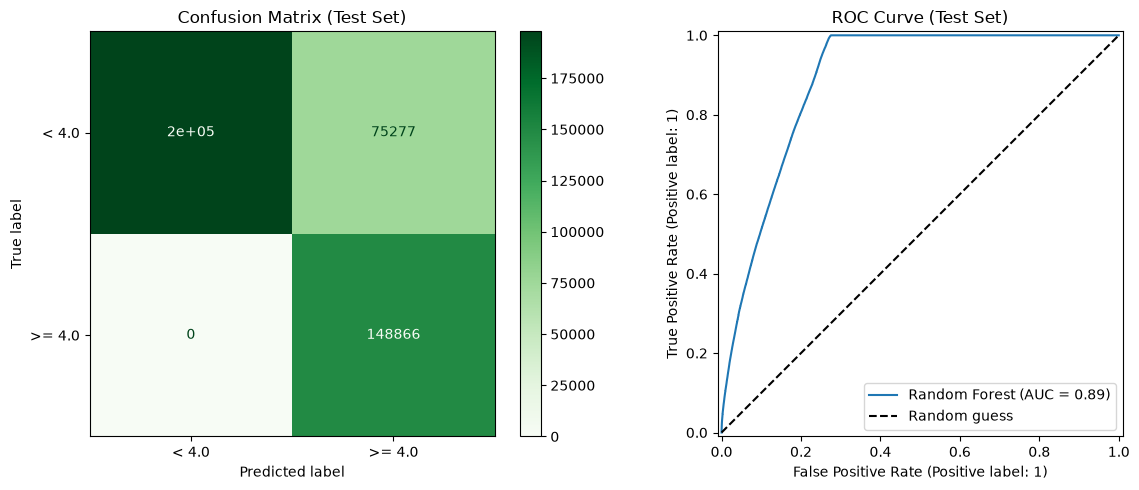

5-fold CV ROC-AUC: 0.901 ± 0.003


In [9]:
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (classification_report, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.model_selection import cross_val_score

rf_pipeline = fitted_pipeline['Random Forest']
y_pred = rf_pipeline.predict(X_test)
y_proba = rf_pipeline.predict_proba(X_test)[:, 1]

# 1. Baseline vs model
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train_binary)
print(f"Baseline accuracy: {baseline.score(X_test, y_test_binary):.3f}")
print(f"Model accuracy:    {rf_pipeline.score(X_test, y_test_binary):.3f}")
print(f"Model ROC-AUC:     {roc_auc_score(y_test_binary, y_proba):.3f}\n")

# 2. Per-class metrics
print(classification_report(y_test_binary, y_pred,
                            target_names=["< 4.0", ">= 4.0"]))

# 3. Confusion matrix and ROC curve side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_binary, y_pred, display_labels=["< 4.0", ">= 4.0"],
    cmap="Greens", ax=axes[0])
axes[0].set_title("Confusion Matrix (Test Set)")
RocCurveDisplay.from_predictions(y_test_binary, y_proba, ax=axes[1],
                                 name="Random Forest")
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].legend()
axes[1].set_title("ROC Curve (Test Set)")
plt.tight_layout()
plt.show()

# 4. Cross-validated stability (uses the training set only)
cv_auc = cross_val_score(rf_pipeline, X_train, y_train_binary,
                         cv=5, scoring="roc_auc", n_jobs=-1)
print(f"5-fold CV ROC-AUC: {cv_auc.mean():.3f} ± {cv_auc.std():.3f}")

### Simpler Version or the answer with out the graphs

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score

rf_pipeline = fitted_pipeline['Random Forest']

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train_binary)

print(f"Dumb guess accuracy: {baseline.score(X_test, y_test_binary):.3f}")
print(f"Random Forest accuracy: {rf_pipeline.score(X_test, y_test_binary):.3f}")
print(f"Random Forest ROC-AUC:  {roc_auc_score(y_test_binary, rf_pipeline.predict_proba(X_test)[:, 1]):.3f}")

Dumb guess accuracy: 0.647
Random Forest accuracy: 0.822
Random Forest ROC-AUC:  0.890


# The streamlined version of the code

In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score

# 1. Load and clean
df = pd.read_csv('Applications_Compiled.csv')
df['LastUpdated'] = pd.to_datetime(df['LastUpdated'], errors='coerce')
df = df.drop_duplicates(subset='AppName').dropna(subset=['Rating'])
df['Days_Since_Update'] = (df['LastUpdated'].max() - df['LastUpdated']).dt.days

# 2. Features and target
num_cols = ['ReviewCount', 'Size_MB', 'Installs', 'Price', 'Days_Since_Update']
cat_cols = ['Category', 'ContentRating', 'Type', 'MinAndroidVer']
X = df[num_cols + cat_cols]
y = (df['Rating'] >= 4.0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Preprocessing + model
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy='median'), num_cols),
    ("cat", make_pipeline(SimpleImputer(strategy='most_frequent'),
                          OneHotEncoder(handle_unknown='ignore')), cat_cols),
])
model = make_pipeline(
    preprocessor,
    RandomForestClassifier(n_estimators=100, max_depth=11,
                           random_state=42, class_weight='balanced'))
model.fit(X_train, y_train)

# 4. Answer the question
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Dumb guess accuracy:    {baseline.score(X_test, y_test):.3f}")
print(f"Random Forest accuracy: {model.score(X_test, y_test):.3f}")
print(f"Random Forest ROC-AUC:  {roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]):.3f}")

Dumb guess accuracy:    0.647
Random Forest accuracy: 0.822
Random Forest ROC-AUC:  0.898
